# Dataset Preparation

## Objective

Prepare and validate three standard image compression
benchmark datasets:

1. Kodak
2. Tecnick
3. CLIC Validation

## Purpose

These datasets will be used to evaluate classical
and learned image compression algorithms under
a unified experimental protocol.

## Dataset Requirements

- Preserve original image resolution.
- Validate image integrity.
- Record image dimensions and formats.
- Generate reproducible metadata.
- Identify corrupted or missing images.
- Maintain consistent preprocessing.

## Expected Outputs

1. Validated dataset directories.
2. Dataset metadata CSV.
3. Dataset validation report.
4. Dataset statistics.
5. Dataset visualizations.

**Environment Setup**

In [3]:
!pip -q install pillow pandas matplotlib requests

In [4]:

from pathlib import Path

ROOT = Path("/content/DIP_Project")

folders = [
    "datasets/kodak",
    "datasets/tecnick",
    "datasets/clic_validation",
    "reports",
    "results",
    "figures",
    "configs",
    "logs"
]

for folder in folders:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

print("Project folders created!")


Project folders created!


# Kodak Dataset Preparation

## Objective

Prepare the Kodak Lossless True Color Image Suite
for classical and learned image compression
benchmarking.

## Tasks

1. Download all 24 Kodak images.
2. Verify image integrity and format.
3. Check image dimensions and color mode.
4. Display sample images for visual inspection.
5. Record dataset metadata.

In [6]:

import requests
from PIL import Image

kodak_folder = ROOT / "datasets/kodak"

base_url = "https://r0k.us/graphics/kodak/kodak/"

for i in range(1, 25):
    filename = f"kodim{i:02d}.png"
    path = kodak_folder / filename
    url = base_url + filename

    try:
        if not path.exists():
            response = requests.get(
                url,
                timeout=30
            )
            response.raise_for_status()
            path.write_bytes(response.content)

        with Image.open(path) as img:
            if img.format != "PNG":
                raise ValueError("Unexpected image format")
            img.verify()

        print("OK:", filename)

    except Exception as e:
        path.unlink(missing_ok=True)
        print("FAILED:", filename, str(e))

print(
    "Files downloaded:",
    len(list(kodak_folder.glob("*.png")))
)


OK: kodim01.png
OK: kodim02.png
OK: kodim03.png
OK: kodim04.png
OK: kodim05.png
OK: kodim06.png
OK: kodim07.png
OK: kodim08.png
OK: kodim09.png
OK: kodim10.png
OK: kodim11.png
OK: kodim12.png
OK: kodim13.png
OK: kodim14.png
OK: kodim15.png
OK: kodim16.png
OK: kodim17.png
OK: kodim18.png
OK: kodim19.png
OK: kodim20.png
OK: kodim21.png
OK: kodim22.png
OK: kodim23.png
OK: kodim24.png
Files downloaded: 24


In [ ]:

import pandas as pd
from PIL import Image

records = []

dataset_folders = {
    "Kodak": ROOT / "datasets/kodak",
    "Tecnick": ROOT / "datasets/tecnick",
    "CLIC": ROOT / "datasets/clic_validation"
}

for dataset_name, folder in dataset_folders.items():
    for path in sorted(folder.rglob("*")):
        if not path.is_file():
            continue

        try:
            with Image.open(path) as img:
                if img.format not in ("PNG", "TIFF", "BMP"):
                    continue

                records.append({
                    "Dataset": dataset_name,
                    "Filename": path.name,
                    "Width": img.width,
                    "Height": img.height,
                    "Format": img.format,
                    "Color Mode": img.mode,
                    "Size KB": round(
                        path.stat().st_size / 1024, 2
                    )
                })

        except Exception as error:
            print("Skipped:", path.name, error)

df = pd.DataFrame(records)

output = ROOT / "reports/dataset_information.csv"
df.to_csv(output, index=False)

display(df)

print("Number of images:", len(df))
print("Report saved:", output)


,Dataset,Filename,Width,Height,Format,Color Mode,Size KB
0,Kodak,kodim01.png,768,512,PNG,RGB,719.24
1,Kodak,kodim02.png,768,512,PNG,RGB,603.51
2,Kodak,kodim03.png,768,512,PNG,RGB,491.10
3,Kodak,kodim04.png,512,768,PNG,RGB,622.49
4,Kodak,kodim05.png,768,512,PNG,RGB,767.20
5,Kodak,kodim06.png,768,512,PNG,RGB,604.45
6,Kodak,kodim07.png,768,512,PNG,RGB,553.05
7,Kodak,kodim08.png,768,512,PNG,RGB,769.99
8,Kodak,kodim09.png,512,768,PNG,RGB,569.24
9,Kodak,kodim10.png,512,768,PNG,RGB,579.55


Number of images: 24
Report saved: /content/DIP_Project/reports/dataset_information.csv


In [ ]:

from google.colab import files

files.download(str(output))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Verify your dataset**

In [ ]:

from PIL import Image

valid = 0

for i in range(1, 25):
    filename = f"kodim{i:02d}.png"
    path = kodak_folder / filename

    try:
        with Image.open(path) as img:
            assert img.format == "PNG"
            assert img.mode == "RGB"
            img.verify()

        valid += 1
        print("PASS:", filename)

    except Exception as error:
        print("FAIL:", filename, error)

print(f"\nVerified: {valid}/24")

assert valid == 24, "Dataset incomplete!"


PASS: kodim01.png
PASS: kodim02.png
PASS: kodim03.png
PASS: kodim04.png
PASS: kodim05.png
PASS: kodim06.png
PASS: kodim07.png
PASS: kodim08.png
PASS: kodim09.png
PASS: kodim10.png
PASS: kodim11.png
PASS: kodim12.png
PASS: kodim13.png
PASS: kodim14.png
PASS: kodim15.png
PASS: kodim16.png
PASS: kodim17.png
PASS: kodim18.png
PASS: kodim19.png
PASS: kodim20.png
PASS: kodim21.png
PASS: kodim22.png
PASS: kodim23.png
PASS: kodim24.png

Verified: 24/24


# Tecnick Dataset Preparation

## Objective

Prepare the Tecnick image dataset for compression
benchmarking.

The dataset contains high-resolution images
suitable for evaluating compression algorithms.

## Tasks

1. Obtain the official dataset.
2. Extract images.
3. Verify image formats.
4. Check dataset completeness.

In [13]:
from google.colab import files
from pathlib import Path
import zipfile
import tarfile

tecnick_folder = ROOT / "datasets/tecnick"
tecnick_folder.mkdir(parents=True, exist_ok=True)

print("Upload the Tecnick dataset archive:")

uploaded = files.upload()

for filename, content in uploaded.items():

    archive_path = ROOT / Path(filename).name
    archive_path.write_bytes(content)

    if zipfile.is_zipfile(archive_path):

        with zipfile.ZipFile(archive_path) as archive:
            archive.extractall(tecnick_folder)

    elif tarfile.is_tarfile(archive_path):

        with tarfile.open(archive_path) as archive:
            archive.extractall(
                tecnick_folder,
                filter="data"
            )

    else:
        print("Unsupported archive:", filename)

Upload the Tecnick dataset archive:


Saving testimages.zip to testimages.zip


In [14]:
image_extensions = {".png", ".tif", ".tiff", ".bmp"}

tecnick_images = [
    p for p in tecnick_folder.rglob("*")
    if p.is_file()
    and p.suffix.lower() in image_extensions
]

print("Tecnick images found:", len(tecnick_images))

Tecnick images found: 2700


# CLIC Validation Dataset Preparation

## Objective

Prepare the CLIC validation dataset for
learned and classical image compression
benchmarking.

## Tasks

1. Obtain the designated validation dataset.
2. Extract all images.
3. Verify image integrity.
4. Record dataset metadata.

In [15]:
from google.colab import files
from pathlib import Path
import zipfile

clic_folder = ROOT / "datasets/clic_validation"
clic_folder.mkdir(parents=True, exist_ok=True)

print("Upload CLIC validation archive:")

uploaded = files.upload()

for filename, content in uploaded.items():

    archive_path = ROOT / Path(filename).name
    archive_path.write_bytes(content)

    if zipfile.is_zipfile(archive_path):

        with zipfile.ZipFile(archive_path) as archive:
            archive.extractall(clic_folder)

    else:
        print("Expected a ZIP archive:", filename)

Upload CLIC validation archive:


Saving clic2024_image_test.zip to clic2024_image_test.zip


In [16]:
clic_images = [
    p for p in clic_folder.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".png", ".jpg", ".jpeg"}
]

print("CLIC images found:", len(clic_images))

CLIC images found: 32


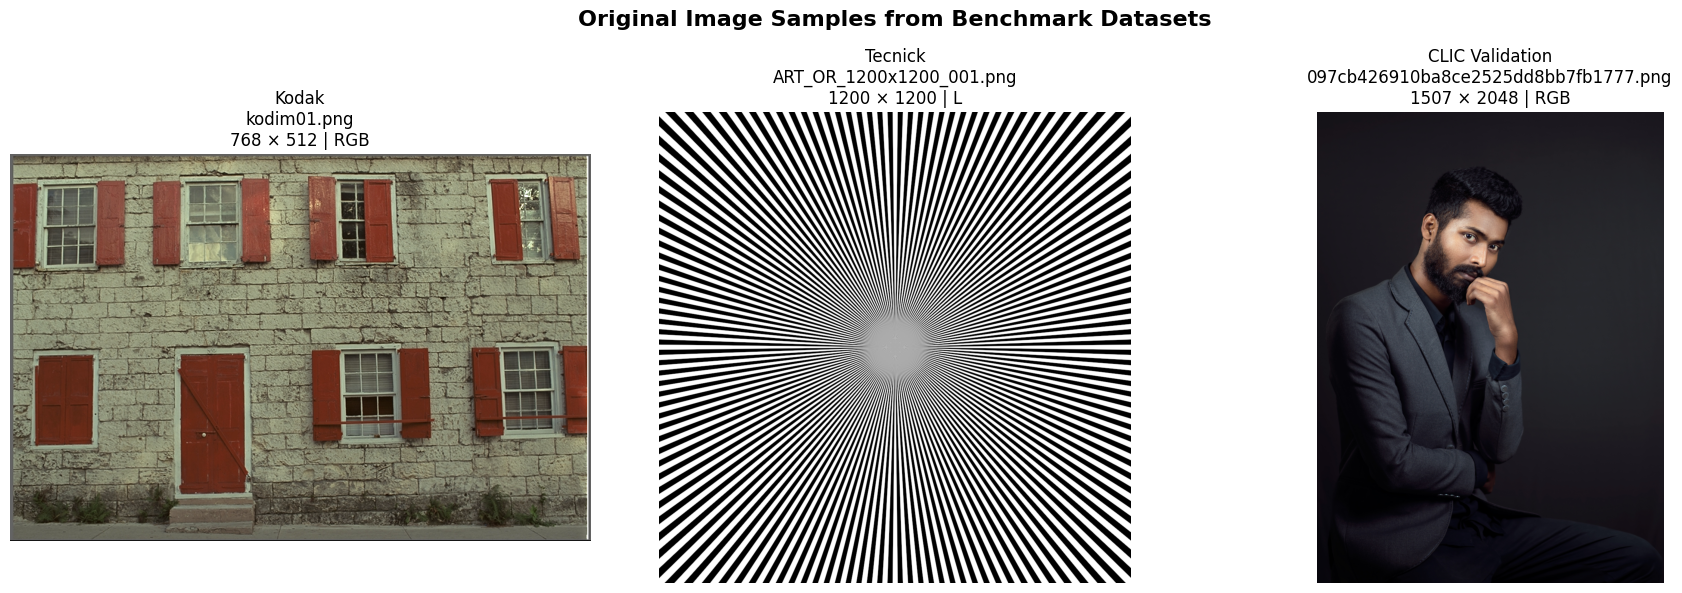

In [28]:
from PIL import Image
import matplotlib.pyplot as plt

datasets = {
    "Kodak": ROOT / "datasets/kodak",
    "Tecnick": ROOT / "datasets/tecnick",
    "CLIC Validation": ROOT / "datasets/clic_validation"
}

image_extensions = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (dataset_name, folder) in zip(axes, datasets.items()):

    images = sorted([
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    ])

    if not images:
        ax.set_title(f"{dataset_name}\nNo images found")
        ax.axis("off")
        continue

    image_path = images[0]

    with Image.open(image_path) as img:
        dimensions = img.size
        color_mode = img.mode
        image = img.convert("RGB")

    ax.imshow(image)

    ax.set_title(
        f"{dataset_name}\n"
        f"{image_path.name}\n"
        f"{dimensions[0]} × {dimensions[1]} | {color_mode}"
    )

    ax.axis("off")

plt.suptitle(
    "Original Image Samples from Benchmark Datasets",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Metadata report for Kodak, Tecnick, and CLIC**

In [30]:
import pandas as pd
from PIL import Image
from pathlib import Path

records = []

dataset_folders = {
    "Kodak": ROOT / "datasets/kodak",
    "Tecnick": ROOT / "datasets/tecnick",
    "CLIC": ROOT / "datasets/clic_validation"
}

image_extensions = {
    ".png", ".jpg", ".jpeg",
    ".tif", ".tiff", ".bmp"
}

for dataset_name, folder in dataset_folders.items():

    print(f"\nProcessing {dataset_name} dataset...")

    if not folder.exists():
        print(f"Dataset folder not found: {folder}")
        continue

    for path in sorted(folder.rglob("*")):

        if not path.is_file():
            continue

        if path.suffix.lower() not in image_extensions:
            continue

        try:
            # Verify image integrity
            with Image.open(path) as img:
                img.verify()

            # Reopen image to extract metadata
            with Image.open(path) as img:
                img.load()

                records.append({
                    "Dataset": dataset_name,
                    "Filename": path.name,
                    "Width": img.width,
                    "Height": img.height,
                    "Resolution": f"{img.width} × {img.height}",
                    "Format": img.format,
                    "Color Mode": img.mode,
                    "Size KB": round(
                        path.stat().st_size / 1024, 2
                    ),
                    "Status": "PASS"
                })

            print("OK:", path.name)

        except Exception as error:
            print("FAILED:", path.name, str(error))

            records.append({
                "Dataset": dataset_name,
                "Filename": path.name,
                "Width": None,
                "Height": None,
                "Resolution": None,
                "Format": None,
                "Color Mode": None,
                "Size KB": round(
                    path.stat().st_size / 1024, 2
                ),
                "Status": "FAIL"
            })


# Create DataFrame
df = pd.DataFrame(records, columns=[
    "Dataset", "Filename", "Width", "Height",
    "Resolution", "Format", "Color Mode",
    "Size KB", "Status"
])

# Create reports folder
reports_folder = ROOT / "reports"
reports_folder.mkdir(parents=True, exist_ok=True)

# Save metadata
output = reports_folder / "dataset_information.csv"

df.to_csv(output, index=False)

print("\n========== DATASET METADATA ==========")

display(df)

print("\nTotal images processed:", len(df))
print("Report saved:", output)


Processing Kodak dataset...
OK: kodim01.png
OK: kodim02.png
OK: kodim03.png
OK: kodim04.png
OK: kodim05.png
OK: kodim06.png
OK: kodim07.png
OK: kodim08.png
OK: kodim09.png
OK: kodim10.png
OK: kodim11.png
OK: kodim12.png
OK: kodim13.png
OK: kodim14.png
OK: kodim15.png
OK: kodim16.png
OK: kodim17.png
OK: kodim18.png
OK: kodim19.png
OK: kodim20.png
OK: kodim21.png
OK: kodim22.png
OK: kodim23.png
OK: kodim24.png

Processing Tecnick dataset...
OK: ART_OR_1200x1200_001.png
OK: ART_OR_1200x1200_002.png
OK: ART_OR_1200x1200_003.png
OK: ART_OR_1200x1200_004.png
OK: ART_OR_1200x1200_005.png
OK: ART_OR_1200x1200_006.png
OK: ART_OR_1200x1200_007.png
OK: ART_OR_1200x1200_008.png
OK: ART_OR_1200x1200_009.png
OK: ART_OR_1200x1200_010.png
OK: ART_OR_1200x1200_011.png
OK: ART_OR_1200x1200_012.png
OK: ART_OR_1200x1200_013.png
OK: ART_OR_1200x1200_014.png
OK: ART_OR_1200x1200_015.png
OK: ART_OR_1200x1200_016.png
OK: ART_OR_1200x1200_017.png
OK: ART_OR_1200x1200_018.png
OK: ART_OR_1200x1200_019.png
OK: A

,Dataset,Filename,Width,Height,Resolution,Format,Color Mode,Size KB,Status
0,Kodak,kodim01.png,768,512,768 × 512,PNG,RGB,719.24,PASS
1,Kodak,kodim02.png,768,512,768 × 512,PNG,RGB,603.51,PASS
2,Kodak,kodim03.png,768,512,768 × 512,PNG,RGB,491.10,PASS
3,Kodak,kodim04.png,512,768,512 × 768,PNG,RGB,622.49,PASS
4,Kodak,kodim05.png,768,512,768 × 512,PNG,RGB,767.20,PASS
...,...,...,...,...,...,...,...,...,...
2751,CLIC,c80999cd5533e448167cd9b3ccfa2a37.png,2048,878,2048 × 878,PNG,RGB,3197.30,PASS
2752,CLIC,d1a9be98d1936065967adac50a6fb750.png,2048,1270,2048 × 1270,PNG,RGB,2142.75,PASS
2753,CLIC,d79d465ac77c36518e0f0d626bf97ec4.png,1638,2048,1638 × 2048,PNG,RGB,3205.36,PASS
2754,CLIC,ddcd24d99f48eaa369207882a6f37831.png,2048,1365,2048 × 1365,PNG,RGB,3130.25,PASS



Total images processed: 2756
Report saved: /content/DIP_Project/reports/dataset_information.csv


In [31]:
# Generate dataset summary

summary = df.groupby("Dataset").agg(
    Total_Images=("Filename", "count"),
    Valid_Images=("Status", lambda x: (x == "PASS").sum()),
    Failed_Images=("Status", lambda x: (x == "FAIL").sum()),
    Average_Width=("Width", "mean"),
    Average_Height=("Height", "mean"),
    Average_Size_KB=("Size KB", "mean")
).reset_index()

# Round numerical values
summary = summary.round(2)

# Save summary
summary_output = ROOT / "reports/dataset_summary.csv"

summary.to_csv(summary_output, index=False)

print("========== DATASET SUMMARY ==========")

display(summary)

print("Summary saved:", summary_output)

========== DATASET SUMMARY ==========


,Dataset,Total_Images,Valid_Images,Failed_Images,Average_Width,Average_Height,Average_Size_KB
0,CLIC,32,32,0,1769.81,1630.19,3268.94
1,Kodak,24,24,0,704.00,576.00,626.40
2,Tecnick,2700,2700,0,367.78,367.78,204.93


Summary saved: /content/DIP_Project/reports/dataset_summary.csv


**Validation Function for All Datasets**

In [18]:
from PIL import Image
from pathlib import Path

def validate_image(image_path):

    try:
        # Check whether the file is corrupted
        with Image.open(image_path) as img:
            img.verify()

        # Reopen the image to inspect its properties
        with Image.open(image_path) as img:
            img.load()

            width, height = img.size
            image_format = img.format
            color_mode = img.mode

        if width <= 0 or height <= 0:
            raise ValueError("Invalid image dimensions")

        return {
            "Filename": image_path.name,
            "Width": width,
            "Height": height,
            "Format": image_format,
            "Color Mode": color_mode,
            "Status": "PASS",
            "Error": ""
        }

    except Exception as error:

        return {
            "Filename": image_path.name,
            "Width": None,
            "Height": None,
            "Format": None,
            "Color Mode": None,
            "Status": "FAIL",
            "Error": str(error)
        }


In [19]:
image_path = ROOT / "datasets/kodak/kodim01.png"

result = validate_image(image_path)

print(result)

{'Filename': 'kodim01.png', 'Width': 768, 'Height': 512, 'Format': 'PNG', 'Color Mode': 'RGB', 'Status': 'PASS', 'Error': ''}


**SHA-256 Checksums**


*   SHA-256 generates a unique fingerprint of the image file.
*   If the image changes, its checksum will generally change





In [20]:
import hashlib

def calculate_sha256(file_path):

    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            sha256.update(chunk)

    return sha256.hexdigest()

In [32]:
image_path = ROOT / "datasets/kodak/kodim01.png"

checksum = calculate_sha256(image_path)

print("SHA-256:", checksum)

SHA-256: a56e27cbf5f843c048b6af1d6e090760e9c92fadba88b7dee0205918a37523bd


**Dataset Information CSV**

In [21]:
import pandas as pd

dataset_folders = {
    "Kodak": ROOT / "datasets/kodak",
    "Tecnick": ROOT / "datasets/tecnick",
    "CLIC": ROOT / "datasets/clic_validation"
}

image_extensions = {
    ".png", ".jpg", ".jpeg",
    ".tif", ".tiff", ".bmp"
}

records = []

for dataset_name, folder in dataset_folders.items():

    for path in sorted(folder.rglob("*")):

        if not path.is_file():
            continue

        # Skip unrelated files
        if path.suffix.lower() not in image_extensions:
            continue

        result = validate_image(path)

        result["Dataset"] = dataset_name

        result["Relative Path"] = str(
            path.relative_to(ROOT)
        )

        result["Size KB"] = round(
            path.stat().st_size / 1024, 2
        )

        result["SHA256"] = calculate_sha256(path)

        records.append(result)

df = pd.DataFrame(records)

output = ROOT / "reports/dataset_information.csv"

df.to_csv(output, index=False)

display(df)

print("Total images:", len(df))
print("Metadata saved:", output)

,Filename,Width,Height,Format,Color Mode,Status,Error,Dataset,Relative Path,Size KB,SHA256
0,kodim01.png,768,512,PNG,RGB,PASS,,Kodak,datasets/kodak/kodim01.png,719.24,a56e27cbf5f843c048b6af1d6e090760e9c92fadba88b7...
1,kodim02.png,768,512,PNG,RGB,PASS,,Kodak,datasets/kodak/kodim02.png,603.51,4f4b74a79237e311d72cad958237b5f7088d8bce1c8230...
2,kodim03.png,768,512,PNG,RGB,PASS,,Kodak,datasets/kodak/kodim03.png,491.10,e25ca1ff2f0c0cb5fdfd5f9b0a0bb21ac4c3de3c84a67f...
3,kodim04.png,512,768,PNG,RGB,PASS,,Kodak,datasets/kodak/kodim04.png,622.49,e3b946107c5d3441c022f678d0c3caf1e224d81b1604ba...
4,kodim05.png,768,512,PNG,RGB,PASS,,Kodak,datasets/kodak/kodim05.png,767.20,10349e963c5c813d327852f82c1795fa4148d69fedffc4...
...,...,...,...,...,...,...,...,...,...,...,...
2751,c80999cd5533e448167cd9b3ccfa2a37.png,2048,878,PNG,RGB,PASS,,CLIC,datasets/clic_validation/c80999cd5533e448167cd...,3197.30,d40eb4f49c146e0bac5b4d43af71c2a8fddfd4964e4a92...
2752,d1a9be98d1936065967adac50a6fb750.png,2048,1270,PNG,RGB,PASS,,CLIC,datasets/clic_validation/d1a9be98d1936065967ad...,2142.75,680003ddef09a61e8604c6f681e27482892f6f1edf3f86...
2753,d79d465ac77c36518e0f0d626bf97ec4.png,1638,2048,PNG,RGB,PASS,,CLIC,datasets/clic_validation/d79d465ac77c36518e0f0...,3205.36,280665498758e01701bccc1b91833bda3f5860fc9d5ead...
2754,ddcd24d99f48eaa369207882a6f37831.png,2048,1365,PNG,RGB,PASS,,CLIC,datasets/clic_validation/ddcd24d99f48eaa369207...,3130.25,fac0c52f88921b2a87a04c8b143e7639379fb234db1a2c...


Total images: 2756
Metadata saved: /content/DIP_Project/reports/dataset_information.csv


**Dataset Statistics**

In [22]:
valid_df = df[df["Status"] == "PASS"].copy()

valid_df["Pixels"] = (
    valid_df["Width"] * valid_df["Height"]
)

summary = valid_df.groupby("Dataset").agg(
    Total_Images=("Filename", "count"),
    Average_Width=("Width", "mean"),
    Average_Height=("Height", "mean"),
    Average_Pixels=("Pixels", "mean"),
    Average_Size_KB=("Size KB", "mean")
).reset_index()

display(summary)

summary.to_csv(
    ROOT / "reports/dataset_summary.csv",
    index=False
)

,Dataset,Total_Images,Average_Width,Average_Height,Average_Pixels,Average_Size_KB
0,CLIC,32,1769.812500,1630.187500,2.768896e+06,3268.942187
1,Kodak,24,704.000000,576.000000,3.932160e+05,626.396250
2,Tecnick,2700,367.777778,367.777778,2.438333e+05,204.928067


**Dataset Visualizations**

Plot 1: Number of Images per Dataset

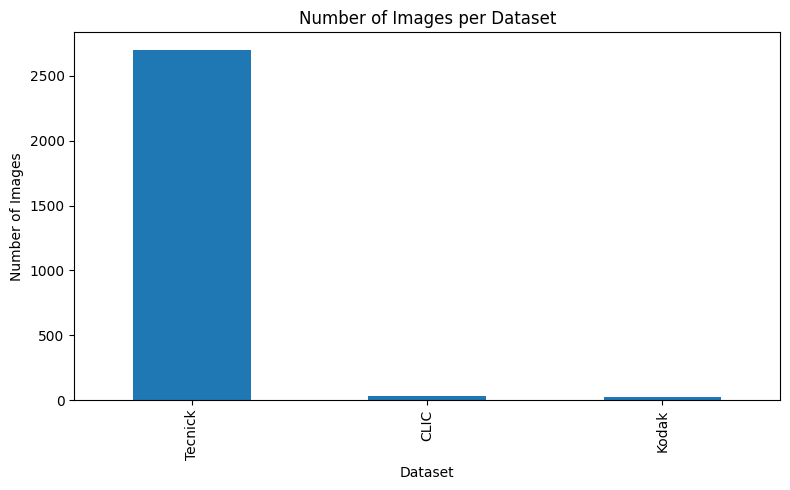

In [23]:
import matplotlib.pyplot as plt

counts = valid_df["Dataset"].value_counts()

plt.figure(figsize=(8, 5))

counts.plot(kind="bar")

plt.title("Number of Images per Dataset")
plt.xlabel("Dataset")
plt.ylabel("Number of Images")

plt.tight_layout()

plt.savefig(
    ROOT / "figures/dataset_counts.png",
    dpi=300
)

plt.show()

Plot 2: Image Resolution Distribution

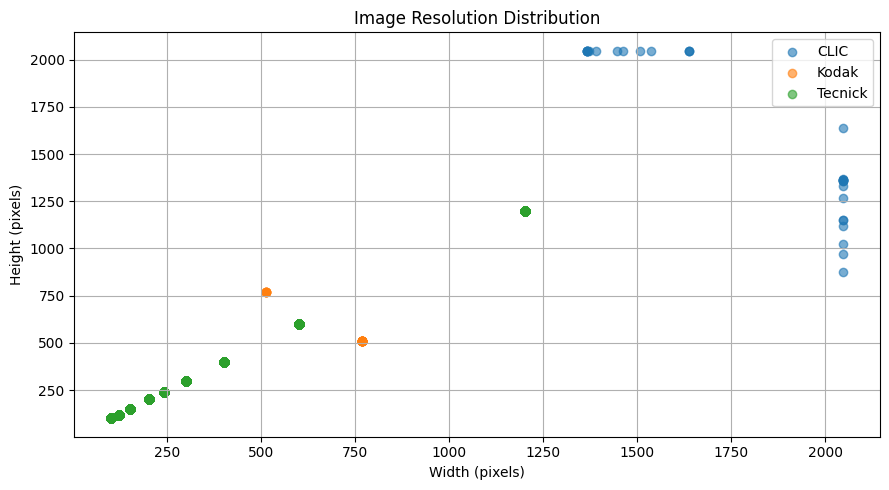

In [24]:
plt.figure(figsize=(9, 5))

for dataset_name, group in valid_df.groupby("Dataset"):

    plt.scatter(
        group["Width"],
        group["Height"],
        label=dataset_name,
        alpha=0.6
    )

plt.title("Image Resolution Distribution")

plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    ROOT / "figures/resolution_distribution.png",
    dpi=300
)

plt.show()

# Image Preprocessing Protocol

## Objective

Establish a consistent preprocessing protocol
for classical and learned image compression.

## 1. Image Resolution

Original image resolutions will be preserved.

No resizing will be applied during the
standard benchmarking experiments.

## 2. Color Representation

Images will be evaluated using a consistent
RGB reference representation.

Any required color conversion will be
documented.

## 3. Image Normalization

For neural compression models, image pixel
values will be normalized to [0, 1] when
required by the model.

Classical codecs will receive inputs in
their supported representation.

## 4. Padding

Padding may be applied to satisfy neural
codec input-size requirements.

Padding will be removed after decoding
and before quality evaluation.

## 5. Image Quality

The original reference image will be used
to calculate reconstruction quality.

## 6. Reproducibility

Dataset versions, image checksums, software
versions, and preprocessing parameters
will be documented.

**Final Validation Report**

In [25]:
validation_summary = df.groupby(
    ["Dataset", "Status"]
).size().unstack(fill_value=0)

display(validation_summary)

validation_summary.to_csv(
    ROOT / "reports/validation_summary.csv"
)

print("Validation report generated successfully!")

Status,PASS
Dataset,
CLIC,32
Kodak,24
Tecnick,2700


Validation report generated successfully!


In [26]:
expected_kodak = {
    f"kodim{i:02d}.png"
    for i in range(1, 25)
}

actual_kodak = set(
    df.loc[
        (df["Dataset"] == "Kodak") &
        (df["Status"] == "PASS"),
        "Filename"
    ]
)

missing_kodak = expected_kodak - actual_kodak

print("Missing Kodak images:", sorted(missing_kodak))

assert not missing_kodak, "Kodak dataset is incomplete!"

Missing Kodak images: []


**Reproducibility Report**

In [27]:
import sys
import platform
import PIL
import pandas
import matplotlib
import requests

environment = {
    "Python": sys.version.split()[0],
    "Platform": platform.platform(),
    "Pillow": PIL.__version__,
    "Pandas": pandas.__version__,
    "Matplotlib": matplotlib.__version__,
    "Requests": requests.__version__
}

environment_df = pd.DataFrame(
    environment.items(),
    columns=["Library", "Version"]
)

display(environment_df)

environment_df.to_csv(
    ROOT / "reports/environment.csv",
    index=False
)

,Library,Version
0,Python,3.13.18
1,Platform,Linux-6.6.159+-x86_64-with-glibc2.39
2,Pillow,11.3.0
3,Pandas,2.2.3
4,Matplotlib,3.10.0
5,Requests,2.32.4




```
Dataset_Preparation.ipynb
│
├── 1. Project Introduction
│
├── 2. Environment Setup
│
├── 3. Project Directory Structure
│
├── 4. Dataset Documentation
│
├── 5. Kodak Dataset Preparation
│
├── 6. Tecnick Dataset Preparation
│
├── 7. CLIC Dataset Preparation
│
├── 8. Image Validation
│
├── 9. SHA-256 Checksum Generation
│
├── 10. Dataset Metadata Extraction
│
├── 11. Dataset Statistical Analysis
│
├── 12. Dataset Visualizations
│
├── 13. Preprocessing Protocol
│
├── 14. Final Validation Report
│
└── 15. Reproducibility Documentation
```

